<a href="https://colab.research.google.com/github/muruganharish123/Emotion-detection-project/blob/main/Emotion_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
train=pd.read_csv("training.csv")
test=pd.read_csv("test.csv")
validation=pd.read_csv("validation.csv")

#No of rows and columns
print("Train:", train.shape)
print("Test:", test.shape)
print("Validation:", validation.shape)

Train: (16000, 2)
Test: (2000, 2)
Validation: (2000, 2)


In [ ]:
print(train.head())
print(train.columns)
print(train.shape)

print(validation.shape)
print(test.shape)

                                                text  label
0                            i didnt feel humiliated      0
1  i can go from feeling so hopeless to so damned...      0
2   im grabbing a minute to post i feel greedy wrong      3
3  i am ever feeling nostalgic about the fireplac...      2
4                               i am feeling grouchy      3
Index(['text', 'label'], dtype='object')
(16000, 2)
(2000, 2)
(2000, 2)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    16000 non-null  object
 1   label   16000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 250.1+ KB
None
text     0
label    0
dtype: int64

Emotion Counts:

label
1    5362
0    4666
3    2159
4    1937
2    1304
5     572
Name: count, dtype: int64


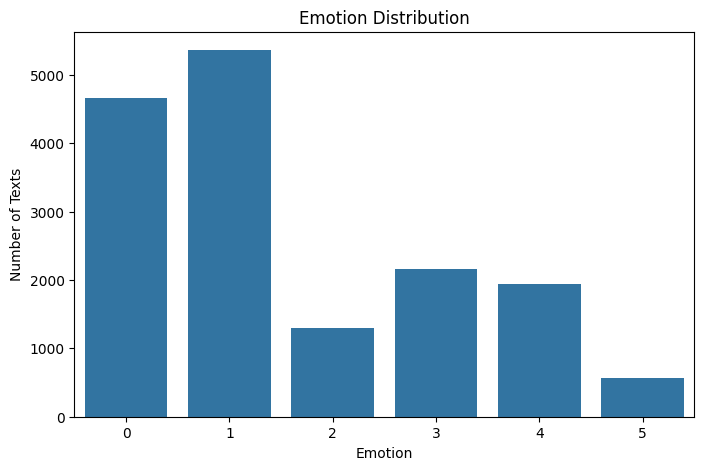

In [ ]:
#Checking data
print(train.info())
print(train.isnull().sum())

print("\nEmotion Counts:\n")
print(train["label"].value_counts())

#graphical
plt.figure(figsize=(8,5))

sns.countplot(data=train, x="label")

plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Texts")

plt.show()

In [ ]:
#text preprocessing
print(train["text"].head(10))

#cleaning text
import re
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

train["clean_text"]=train["text"].apply(clean_text)
test["clean_text"]=test["text"].apply(clean_text)
validation["clean_text"]=validation["text"].apply(clean_text)

0                              i didnt feel humiliated
1    i can go from feeling so hopeless to so damned...
2     im grabbing a minute to post i feel greedy wrong
3    i am ever feeling nostalgic about the fireplac...
4                                 i am feeling grouchy
5    ive been feeling a little burdened lately wasn...
6    ive been taking or milligrams or times recomme...
7    i feel as confused about life as a teenager or...
8    i have been with petronas for years i feel tha...
9                                  i feel romantic too
Name: text, dtype: object


In [ ]:
#test train split
X_train = train["clean_text"]
y_train = train["label"]

X_test = test["clean_text"]
y_test = test["label"]

#encoding
vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
#logistic regression
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

print("\n",classification_report(y_test, y_pred))

Accuracy: 0.8615

               precision    recall  f1-score   support

           0       0.89      0.93      0.91       581
           1       0.83      0.96      0.89       695
           2       0.82      0.58      0.68       159
           3       0.90      0.81      0.85       275
           4       0.87      0.78      0.82       224
           5       0.84      0.47      0.60        66

    accuracy                           0.86      2000
   macro avg       0.86      0.75      0.79      2000
weighted avg       0.86      0.86      0.86      2000



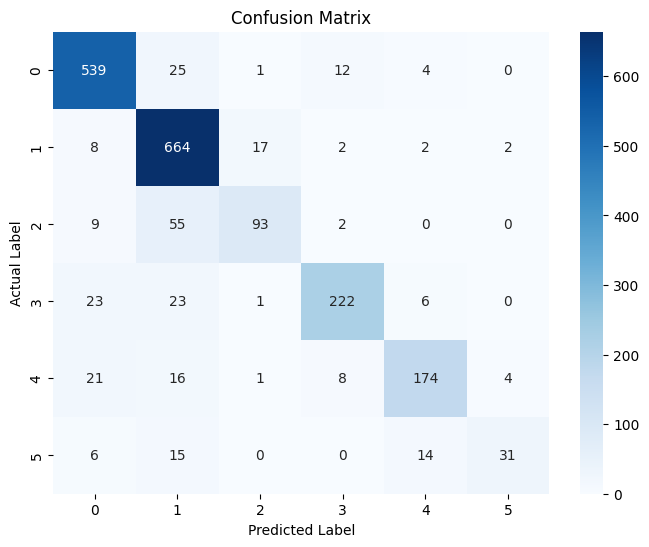

In [ ]:
#confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

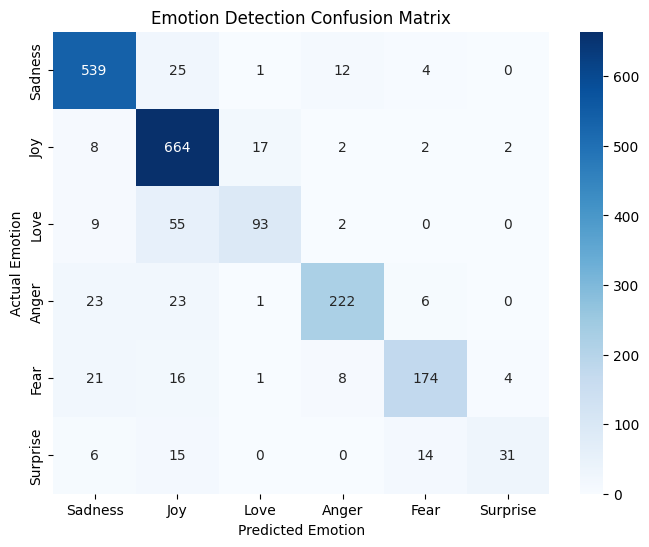

In [ ]:
# emotion labels

emotions = [
    "Sadness",
    "Joy",
    "Love",
    "Anger",
    "Fear",
    "Surprise"
]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotions,
    yticklabels=emotions
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Emotion Detection Confusion Matrix")

plt.show()

In [ ]:
# emotion prediction

def predict_emotion(text):

    text = clean_text(text)

    text_tfidf = vectorizer.transform([text])

    prediction = model.predict(text_tfidf)

    emotions = [
        "Sadness",
        "Joy",
        "Love",
        "Anger",
        "Fear",
        "Surprise"
    ]

    print("Text:", text)
    print("Predicted Emotion:", emotions[prediction[0]])


predict_emotion("I am extremely happy today")

Text: i am extremely happy today
Predicted Emotion: Joy


In [ ]:
predict_emotion("I am feeling very sad")
predict_emotion("I am so angry right now")
predict_emotion("I am scared")
predict_emotion("I love my family")
predict_emotion("Wow, I did not expect that!")

Text: i am feeling very sad
Predicted Emotion: Sadness
Text: i am so angry right now
Predicted Emotion: Anger
Text: i am scared
Predicted Emotion: Fear
Text: i love my family
Predicted Emotion: Joy
Text: wow i did not expect that
Predicted Emotion: Joy
